# Decision Trees (for classification)

# A Decision Tree is a supervised machine learning algorithm used for classification and regression.
# It works like a flowchart or a tree, where:
# Nodes represent features (questions).
# Branches represent answers (possible values).
# Leaves represent the final decision (output).
# It splits data based on feature values to make predictions.


# Real-life Example :
# Scenario: Predict whether a person will play football or not based on:
# Weather: Sunny, Rainy
# Temperature: Hot, Mild, Cool
# Mood: Happy, Sad


# Decision Tree helps answer questions like:
# Is the weather Sunny or Rainy?
# If Sunny, is the temperature Hot or Mild?
# Depending on mood, predict if they play football.

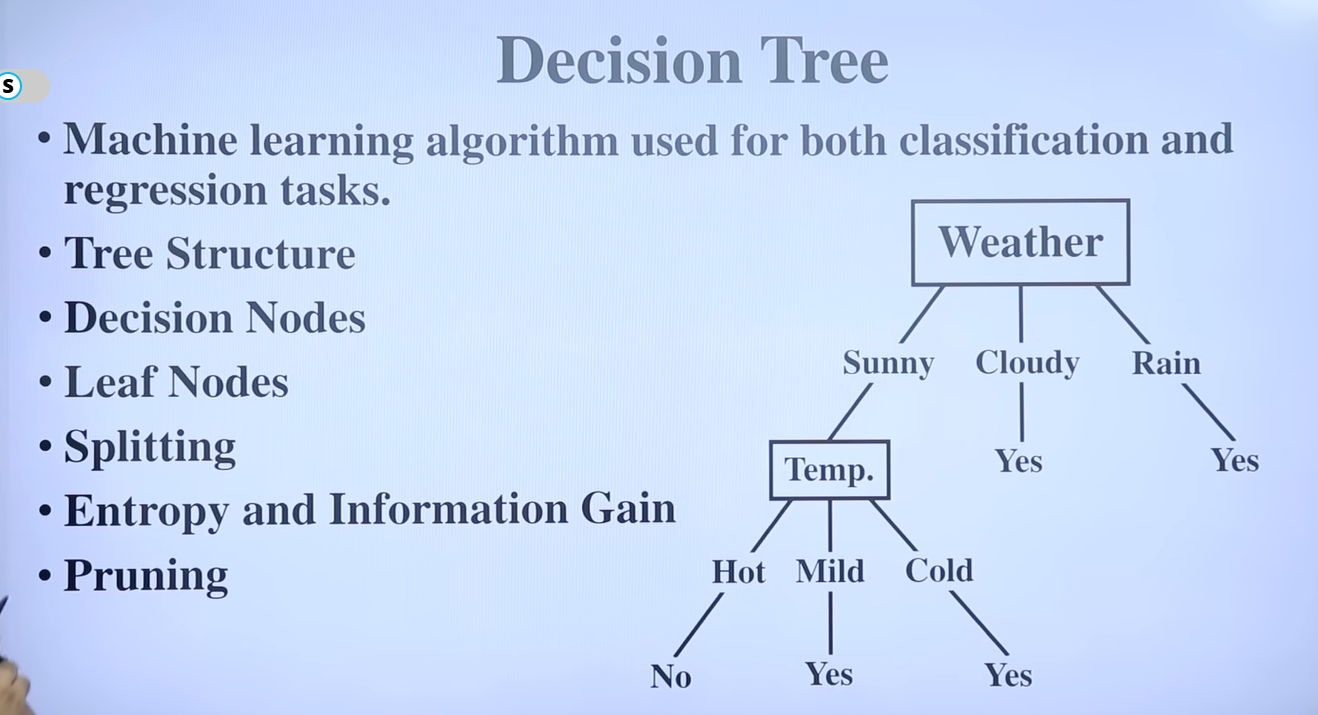

In [2]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

# Sample dataset
data = {
    'Weather': ['Sunny','Sunny','Rainy','Rainy','Sunny','Sunny','Rainy','Rainy'],
    'Temperature': ['Hot','Hot','Mild','Cool','Hot','Mild','Cool','Mild'],
    'Mood': ['Happy','Sad','Happy','Sad','Happy','Sad','Happy','Sad'],
    'Play_Football': ['No','No','Yes','Yes','Yes','No','Yes','No']
}

df = pd.DataFrame(data)

In [3]:
df

,Weather,Temperature,Mood,Play_Football
0,Sunny,Hot,Happy,No
1,Sunny,Hot,Sad,No
2,Rainy,Mild,Happy,Yes
3,Rainy,Cool,Sad,Yes
4,Sunny,Hot,Happy,Yes
5,Sunny,Mild,Sad,No
6,Rainy,Cool,Happy,Yes
7,Rainy,Mild,Sad,No


In [4]:
# Convert categorical variables to numeric
df_encoded = pd.get_dummies(df, columns=['Weather','Temperature','Mood'])

# Features and target
X = df_encoded.drop('Play_Football', axis=1)
y = df_encoded['Play_Football']

# Train Decision Tree Classifier
model = DecisionTreeClassifier(criterion='entropy', random_state=0)
model.fit(X, y)

# Predict for a new person
new_person = pd.DataFrame({
    'Weather_Rainy':[0], 'Weather_Sunny':[1],
    'Temperature_Cool':[0], 'Temperature_Hot':[1], 'Temperature_Mild':[0],
    'Mood_Happy':[1], 'Mood_Sad':[0]
})
prediction = model.predict(new_person)

print("Predicted Decision of Playing football :", prediction[0])

# Visualize the tree rules
tree_rules = export_text(model, feature_names=list(X.columns))
print("\nDecision Tree Rules:\n", tree_rules)

Predicted Decision of Playing football : No

Decision Tree Rules:
 |--- Temperature_Cool <= 0.50
|   |--- Mood_Sad <= 0.50
|   |   |--- Temperature_Hot <= 0.50
|   |   |   |--- class: Yes
|   |   |--- Temperature_Hot >  0.50
|   |   |   |--- class: No
|   |--- Mood_Sad >  0.50
|   |   |--- class: No
|--- Temperature_Cool >  0.50
|   |--- class: Yes



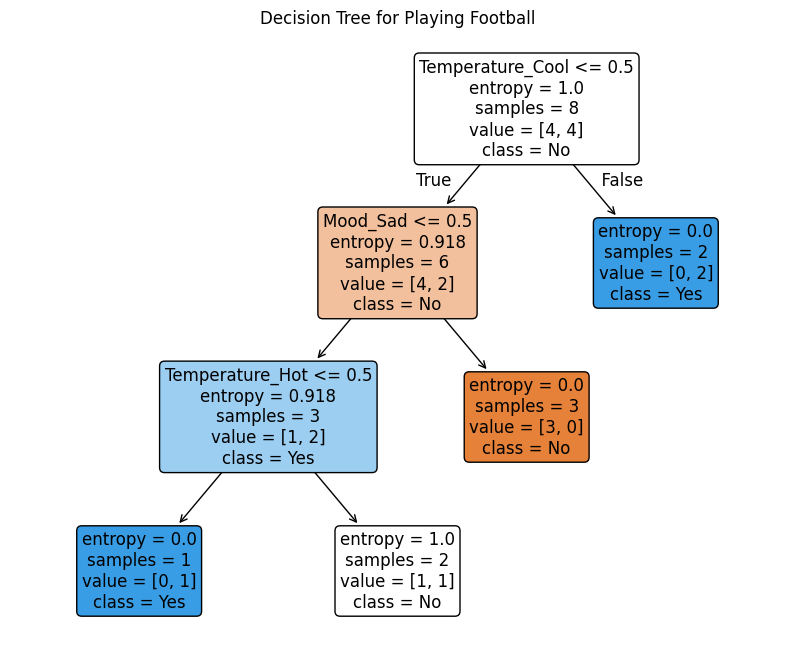

In [6]:
from sklearn.tree import plot_tree
from matplotlib import pyplot as plt

# Visualize the Decision Tree
plt.figure(figsize=(10,8))
plot_tree(model,
          feature_names=X.columns,
          class_names=model.classes_,
          filled=True,
          rounded=True,
          fontsize=12)
plt.title("Decision Tree for Playing Football")
plt.show()

# With ID3 Algorithm 

# Decision Tree using the ID3 algorithm, 

# which uses Entropy and Information Gain to decide how to split data for classification. 

# The goal is to predict whether a game football should be played based on weather conditions: Weather, Temperature, Humidity, and Wind 

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

# Sample dataset
data = {
    "Weather": [
        "Sunny", "Sunny", "Cloudy", "Rain",
        "Rain", "Rain", "Cloudy", "Sunny",
        "Sunny", "Rain", "Sunny", "Cloudy",
        "Cloudy", "Rain"
    ],

    "Temperature": [
        "Hot", "Hot", "Hot", "Mild",
        "Cool", "Cool", "Cool", "Mild",
        "Cool", "Mild", "Mild", "Mild",
        "Hot", "Mild"
    ],

    "Humidity": [
        "High", "High", "High", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "High"
    ],

    "Wind": [
        "Weak", "Strong", "Weak", "Weak",
        "Weak", "Strong", "Strong", "Weak",
        "Weak", "Weak", "Strong", "Strong",
        "Weak", "Strong"
    ],

    "Play_Football": [
        "No", "No", "Yes", "Yes",
        "Yes", "No", "Yes", "No",
        "Yes", "Yes", "Yes", "Yes",
        "Yes", "No"
    ]
}

# Convert dictionary into DataFrame
df = pd.DataFrame(data)

In [9]:
df

,Weather,Temperature,Humidity,Wind,Play_Football
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Cloudy,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Cloudy,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [10]:
print("Total Records:", len(df))

print("\nTarget Distribution:")
print(df["Play_Football"].value_counts())

Total Records: 14

Target Distribution:
Play_Football
Yes    9
No     5
Name: count, dtype: int64


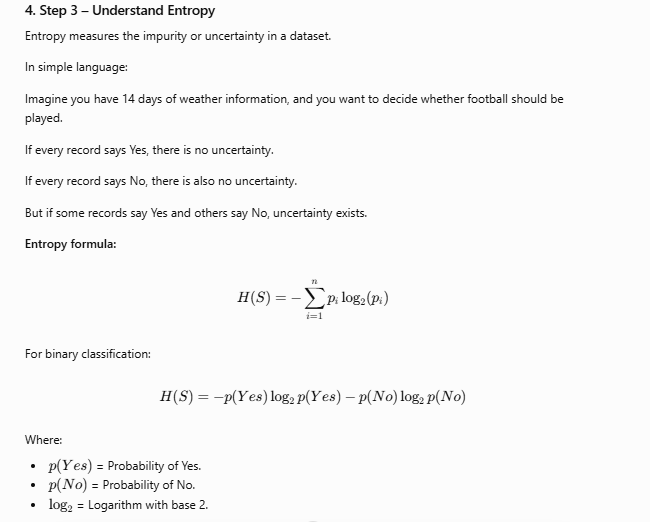

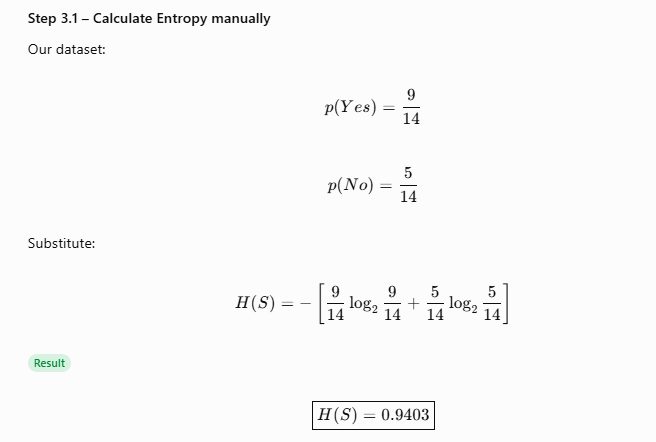

In [12]:
import math

def entropy(data):
    
    # Count occurrences of each class
    counts = data.value_counts()

    # Total number of records
    total = len(data)

    # Initialize entropy
    entropy_value = 0

    # Calculate probability and entropy
    for count in counts:

        probability = count / total

        entropy_value -= probability * math.log2(probability)

    return entropy_value


# Calculate overall entropy
target_entropy = entropy(df["Play_Football"])

print("Total Dataset Entropy:", target_entropy)

Total Dataset Entropy: 0.9402859586706311


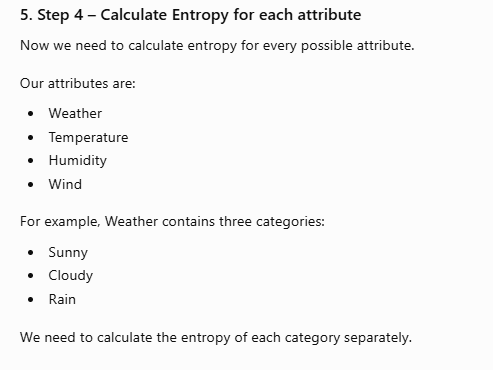